In [ ]:
# =====================================================
# 🧠 ViT Fine-Tuning for Skin Type Classification (Enhanced)
# =====================================================

from google.colab import drive
drive.mount('/content/drive')

import torch, os, numpy as np
from torch import nn, optim
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms
from transformers import ViTForImageClassification, get_cosine_schedule_with_warmup
from tqdm import tqdm

# ----------------------------
# ⚙️ Config
# ----------------------------
DATA_PATH = '/content/drive/MyDrive/Oily-Dry-Skin-Types'
NUM_CLASSES = 3
BATCH_SIZE = 16
IMG_SIZE = 224
PHASE1_EPOCHS = 5
PHASE2_EPOCHS = 8
LR_HEAD = 3e-5
LR_FT = 1e-5
WARMUP_STEPS = 100
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ----------------------------
# 🎨 Data Augmentation
# ----------------------------
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25),
    transforms.RandomAffine(degrees=0, shear=8, scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
])

# ----------------------------
# 📦 Datasets & Sampler
# ----------------------------
train_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'train'), transform=train_tf)
val_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'valid'), transform=eval_tf)
test_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'test'), transform=eval_tf)

# Weighted sampler for balanced batches
class_counts = np.bincount(train_ds.targets)
weights = 1. / class_counts[train_ds.targets]
sampler = WeightedRandomSampler(weights, len(weights))

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=4)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)

# ----------------------------
# 🧩 Model Setup
# ----------------------------
model = ViTForImageClassification.from_pretrained(
    "dima806/skin_types_image_detection",
    num_labels=NUM_CLASSES,
    ignore_mismatched_sizes=True
).to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

# ----------------------------
# 📊 Helper: Evaluate
# ----------------------------
def evaluate(model, loader):
    model.eval()
    total, correct, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outs = model(imgs).logits
            loss = criterion(outs, lbls)
            preds = outs.argmax(1)
            loss_sum += loss.item()
            correct += (preds == lbls).sum().item()
            total += lbls.size(0)
    return correct / total, loss_sum / len(loader)

# ----------------------------
# 🏁 Training Phase 1 (Head Only)
# ----------------------------
for p in model.vit.parameters():
    p.requires_grad = False

optimizer = optim.AdamW(model.parameters(), lr=LR_HEAD, weight_decay=0.01)
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=WARMUP_STEPS,
    num_training_steps=len(train_loader)*PHASE1_EPOCHS
)

best_val = 0
print("🚀 Phase 1: Training classification head")
for ep in range(PHASE1_EPOCHS):
    model.train()
    running_correct, total = 0, 0
    for imgs, lbls in tqdm(train_loader, desc=f"Head Epoch {ep+1}/{PHASE1_EPOCHS}"):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        outs = model(imgs).logits
        loss = criterion(outs, lbls)
        loss.backward()
        optimizer.step()
        scheduler.step()
        running_correct += (outs.argmax(1) == lbls).sum().item()
        total += lbls.size(0)
    train_acc = running_correct / total
    val_acc, _ = evaluate(model, val_loader)
    print(f"Epoch {ep+1}: Train {train_acc:.3f} | Val {val_acc:.3f}")
    if val_acc > best_val:
        best_val = val_acc
        torch.save(model.state_dict(), "vit_skin_best.pt")

print(f"✅ Phase 1 done. Best Val Acc: {best_val:.3f}")

# ----------------------------
# 🔥 Phase 2: Fine-tune top layers
# ----------------------------
print("🔥 Phase 2: Unfreezing top transformer blocks...")
for name, p in model.vit.named_parameters():
    if any(layer in name for layer in ["encoder.layer.10", "encoder.layer.11", "layernorm"]):
        p.requires_grad = True

optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=LR_FT, weight_decay=0.01)
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=WARMUP_STEPS,
    num_training_steps=len(train_loader)*PHASE2_EPOCHS
)

patience, patience_counter = 3, 0
for ep in range(PHASE2_EPOCHS):
    model.train()
    running_correct, total = 0, 0
    for imgs, lbls in tqdm(train_loader, desc=f"Fine-tune {ep+1}/{PHASE2_EPOCHS}"):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        outs = model(imgs).logits
        loss = criterion(outs, lbls)
        loss.backward()
        optimizer.step()
        scheduler.step()
        running_correct += (outs.argmax(1) == lbls).sum().item()
        total += lbls.size(0)
    train_acc = running_correct / total
    val_acc, _ = evaluate(model, val_loader)
    print(f"Fine-tune {ep+1}: Train {train_acc:.3f} | Val {val_acc:.3f}")

    if val_acc > best_val:
        best_val = val_acc
        patience_counter = 0
        torch.save(model.state_dict(), "vit_skin_best.pt")
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("⏸ Early stopping — no improvement.")
            break

# ----------------------------
# 🧪 Final Test
# ----------------------------
model.load_state_dict(torch.load("vit_skin_best.pt"))
test_acc, _ = evaluate(model, test_loader)
print(f"🎯 Final Test Accuracy: {test_acc:.3f}")


Mounted at /content/drive


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/754 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/343M [00:00<?, ?B/s]

🚀 Phase 1: Training classification head


Head Epoch 1/5:   0%|          | 0/173 [00:03<?, ?it/s]


KeyboardInterrupt: 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import torch, os, numpy as np
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from transformers import ViTForImageClassification, ViTConfig
from tqdm import tqdm

# ----------------------------
# ⚙️ Config
# ----------------------------
DATA_PATH = "/tmp/skin_data"
NUM_CLASSES = 3
BATCH_SIZE = 32
IMG_SIZE = 224
EPOCHS = 5

# ----------------------------
# 🎨 Better Transforms
# ----------------------------
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ----------------------------
# 📦 Data Loading with Diagnostics
# ----------------------------
train_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'train'), transform=train_tf)
val_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'valid'), transform=eval_tf)

print("🔍 DATA SUMMARY:")
print(f"Training samples: {len(train_ds)}")
print(f"Validation samples: {len(val_ds)}")
print(f"Classes: {train_ds.classes}")
print(f"Class counts - Train: {np.bincount(train_ds.targets)}")
print(f"Class counts - Val: {np.bincount(val_ds.targets)}")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# ----------------------------
# 🧩 CORRECT Model Setup
# ----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# OPTION 1: Use fresh ViT model (recommended for debugging)
print("🔄 Loading fresh ViT model...")
model = ViTForImageClassification.from_pretrained(
    "dima806/skin_types_image_detection"
    num_labels=NUM_CLASSES,
    id2label={0: "dry", 1: "normal", 2: "oily"},
    label2id={"dry": 0, "normal": 1, "oily": 2},
    ignore_mismatched_sizes=True
)

# OPTION 2: If you want to use your pre-trained model, uncomment this:
# print("🔄 Loading your pre-trained skin model...")
# model = ViTForImageClassification.from_pretrained(
#     "dima806/skin_types_image_detection",
#     num_labels=NUM_CLASSES,
#     ignore_mismatched_sizes=True
# )

model = model.to(device)

# Verify model output dimensions
print(f"Model configured for {model.config.num_labels} classes")

# ----------------------------
# 🏁 Improved Training Loop
# ----------------------------
def evaluate_model(model, loader):
    model.eval()
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model(imgs).logits
            preds = torch.argmax(outputs, dim=1)
            total_correct += (preds == lbls).sum().item()
            total_samples += lbls.size(0)

    return total_correct / total_samples

# Use better optimizer settings
optimizer = optim.AdamW(
    model.parameters(),
    lr=2e-4,  # Increased learning rate
    weight_decay=0.01
)
criterion = nn.CrossEntropyLoss()

print("🚀 Starting training...")

best_val_acc = 0
for epoch in range(EPOCHS):
    # Training phase
    model.train()
    train_loss = 0
    train_correct = 0
    total_samples = 0

    for imgs, lbls in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer.zero_grad()
        outputs = model(imgs).logits
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == lbls).sum().item()
        total_samples += lbls.size(0)

    # Calculate metrics
    train_acc = train_correct / total_samples
    train_loss = train_loss / len(train_loader)

    # Validation phase
    val_acc = evaluate_model(model, val_loader)

    print(f"📊 Epoch {epoch+1} Results:")
    print(f"   Train Loss: {train_loss:.4f}")
    print(f"   Train Acc:  {train_acc:.4f} ({train_correct}/{total_samples})")
    print(f"   Val Acc:    {val_acc:.4f}")
    print(f"   Gap:        {train_acc - val_acc:.4f}")

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_skin_model.pth")
        print(f"   💾 New best model saved! (Val Acc: {val_acc:.4f})")

    print("-" * 50)

print(f"✅ Training completed! Best validation accuracy: {best_val_acc:.4f}")

# Final test on validation set
print("\n🎯 Final validation:")
final_val_acc = evaluate_model(model, val_loader)
print(f"Final Validation Accuracy: {final_val_acc:.4f}")

SyntaxError: invalid syntax. Perhaps you forgot a comma? (ipython-input-4222587592.py, line 63)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import torch, os, numpy as np
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from transformers import ViTForImageClassification
from tqdm import tqdm
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
# ⚙️ Config
# ----------------------------
DATA_PATH = "/content/drive/MyDrive/Oily-Dry-Skin-Types"
NUM_CLASSES = 3
BATCH_SIZE = 32
IMG_SIZE = 224
EPOCHS = 5

# ----------------------------
# 🎨 Transforms
# ----------------------------
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ----------------------------
# 📦 Load ALL Dataset Splits
# ----------------------------
print("📁 LOADING ALL DATASET SPLITS...")

# Train dataset
train_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'train'), transform=train_tf)

# Validation dataset
val_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'valid'), transform=eval_tf)

# Test dataset - FINAL evaluation (not used during training)
test_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'test'), transform=eval_tf)

print("🔍 DATASET SUMMARY:")
print(f"Training samples: {len(train_ds)}")
print(f"Validation samples: {len(val_ds)}")
print(f"Test samples: {len(test_ds)}")
print(f"Classes: {train_ds.classes}")
print(f"Class counts - Train: {np.bincount(train_ds.targets)}")
print(f"Class counts - Val: {np.bincount(val_ds.targets)}")
print(f"Class counts - Test: {np.bincount(test_ds.targets)}")

# Create data loaders
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# ----------------------------
# 🧩 Model Setup
# ----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Create label mappings based on dataset classes
id2label = {i: label for i, label in enumerate(train_ds.classes)}
label2id = {label: i for i, label in enumerate(train_ds.classes)}

print(f"Label mappings: {id2label}")

model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

model = model.to(device)
print(f"✅ Model configured for {model.config.num_labels} classes: {list(id2label.values())}")

# ----------------------------
# 🏁 Training Functions
# ----------------------------
def evaluate_model(model, loader):
    """Comprehensive evaluation with accuracy and predictions"""
    model.eval()
    total_correct = 0
    total_samples = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model(imgs).logits
            preds = torch.argmax(outputs, dim=1)

            total_correct += (preds == lbls).sum().item()
            total_samples += lbls.size(0)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(lbls.cpu().numpy())

    accuracy = total_correct / total_samples
    return accuracy, all_preds, all_labels

def plot_confusion_matrix(cm, classes):
    """Plot confusion matrix"""
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes)
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

# ----------------------------
# 🚀 Training Loop
# ----------------------------
optimizer = optim.AdamW(model.parameters(), lr=2e-4, weight_decay=0.01)
criterion = nn.CrossEntropyLoss()

print("🚀 STARTING TRAINING...")
print("=" * 60)

best_val_acc = 0
for epoch in range(EPOCHS):
    # Training phase
    model.train()
    train_loss = 0
    train_correct = 0
    total_samples = 0

    for imgs, lbls in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer.zero_grad()
        outputs = model(imgs).logits
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == lbls).sum().item()
        total_samples += lbls.size(0)

    # Calculate training metrics
    train_acc = train_correct / total_samples
    train_loss = train_loss / len(train_loader)

    # Validation phase
    val_acc, val_preds, val_labels = evaluate_model(model, val_loader)

    print(f"📊 EPOCH {epoch+1} RESULTS:")
    print(f"   Train Loss: {train_loss:.4f}")
    print(f"   Train Acc:  {train_acc:.4f}")
    print(f"   Val Acc:    {val_acc:.4f}")
    print(f"   Gap:        {train_acc - val_acc:.4f}")

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_skin_model.pth")
        print(f"   💾 New best model saved! (Val Acc: {val_acc:.4f})")

    print("-" * 50)

print(f"✅ TRAINING COMPLETED! Best validation accuracy: {best_val_acc:.4f}")

# ----------------------------
# 🧪 FINAL TEST EVALUATION
# ----------------------------
print("\n" + "=" * 60)
print("🎯 FINAL TEST SET EVALUATION")
print("=" * 60)

# Load best model for final test
model.load_state_dict(torch.load("best_skin_model.pth"))

# Evaluate on test set
test_acc, test_preds, test_labels = evaluate_model(model, test_loader)

print(f"📊 TEST SET RESULTS:")
print(f"   Test Accuracy: {test_acc:.4f}")

# Detailed classification report
print(f"\n📋 CLASSIFICATION REPORT:")
print(classification_report(test_labels, test_preds, target_names=train_ds.classes))

# Confusion matrix
print(f"🎯 CONFUSION MATRIX:")
cm = confusion_matrix(test_labels, test_preds)
plot_confusion_matrix(cm, train_ds.classes)

# Per-class accuracy
print(f"📈 PER-CLASS ACCURACY:")
class_names = train_ds.classes
for i, class_name in enumerate(class_names):
    class_mask = np.array(test_labels) == i
    if np.sum(class_mask) > 0:
        class_acc = np.mean(np.array(test_preds)[class_mask] == i)
        print(f"   {class_name}: {class_acc:.4f} ({np.sum(class_mask)} samples)")

# ----------------------------
# 💾 SAVE FINAL MODEL
# ----------------------------
print(f"\n💾 SAVING FINAL MODEL...")
model.save_pretrained("final_skin_type_model")
print("✅ Model saved to 'final_skin_type_model' folder")

print(f"\n🎉 FINAL SUMMARY:")
print(f"   Best Val Accuracy: {best_val_acc:.4f}")
print(f"   Test Accuracy:     {test_acc:.4f}")
print(f"   Classes:           {list(id2label.values())}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📁 LOADING ALL DATASET SPLITS...
🔍 DATASET SUMMARY:
Training samples: 2756
Validation samples: 262
Test samples: 134
Classes: ['dry', 'normal', 'oily']
Class counts - Train: [ 652 1104 1000]
Class counts - Val: [ 71 111  80]
Class counts - Test: [35 59 40]
Using device: cuda
Label mappings: {0: 'dry', 1: 'normal', 2: 'oily'}


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([3]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 768]) in the checkpoint and torch.Size([3, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


✅ Model configured for 3 classes: ['dry', 'normal', 'oily']
🚀 STARTING TRAINING...


...

📊 EPOCH 3 RESULTS:
   Train Loss: 0.3759
   Train Acc:  0.8505
   Val Acc:    0.4695
   Gap:        0.3810
   💾 New best model saved! (Val Acc: 0.4695)
--------------------------------------------------


Epoch 4/5: 100%|██████████| 87/87 [01:28<00:00,  1.02s/it]


📊 EPOCH 4 RESULTS:
   Train Loss: 0.1539
   Train Acc:  0.9496
   Val Acc:    0.4008
   Gap:        0.5488
--------------------------------------------------


Epoch 5/5:  15%|█▍        | 13/87 [00:14<01:24,  1.15s/it]


KeyboardInterrupt: 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import torch, os, numpy as np
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from transformers import ViTForImageClassification, get_linear_schedule_with_warmup
from tqdm import tqdm

# ----------------------------
# ⚙️ Config - OPTIMIZED
# ----------------------------
DATA_PATH = "/content/drive/MyDrive/Oily-Dry-Skin-Types"
NUM_CLASSES = 3
BATCH_SIZE = 32
IMG_SIZE = 224
EPOCHS = 5

# ----------------------------
# 🎨 BETTER Transforms - SIMPLIFIED
# ----------------------------
# Start with minimal augmentation to help learning
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(0.3),  # Reduced
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ----------------------------
# 📦 Data Loading
# ----------------------------
train_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'train'), transform=train_tf)
val_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'valid'), transform=eval_tf)
test_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'test'), transform=eval_tf)

print("🔍 DATASET CHECK:")
print(f"Train samples: {len(train_ds)}")
print(f"Val samples: {len(val_ds)}")
print(f"Classes: {train_ds.classes}")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# ----------------------------
# 🧩 Model Setup - OPTIMIZED
# ----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Create label mappings
id2label = {i: label for i, label in enumerate(train_ds.classes)}
label2id = {label: i for i, label in enumerate(train_ds.classes)}

print("🔄 Loading ViT model...")
model = ViTForImageClassification.from_pretrained(
    "dima806/skin_types_image_detection",
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True  # This handles the classifier resize warning
)

model = model.to(device)

# ----------------------------
# 🚀 TRAINING SETUP - CRITICAL CHANGES
# ----------------------------

# STRATEGY 1: Freeze backbone, train only head for first epoch
print("🔒 Freezing ViT backbone, training only classification head...")
for name, param in model.named_parameters():
    if "classifier" not in name:  # Freeze all except classifier
        param.requires_grad = False

# BETTER optimizer configuration
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-3,  # HIGHER learning rate for head training
    weight_decay=0.01
)

criterion = nn.CrossEntropyLoss()

def evaluate_model(model, loader):
    model.eval()
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model(imgs).logits
            preds = torch.argmax(outputs, dim=1)
            total_correct += (preds == lbls).sum().item()
            total_samples += lbls.size(0)

    return total_correct / total_samples

print("🚀 STARTING TRAINING WITH FIXED SETUP...")
print("=" * 60)

# PHASE 1: Train only classifier head (1 epoch)
print("🎯 PHASE 1: Training classifier head only...")
model.train()
for epoch in range(1):  # Just one epoch for head
    train_correct = 0
    total_samples = 0

    for imgs, lbls in tqdm(train_loader, desc="Head Training"):
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer.zero_grad()
        outputs = model(imgs).logits
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer.step()

        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == lbls).sum().item()
        total_samples += lbls.size(0)

    train_acc = train_correct / total_samples
    val_acc = evaluate_model(model, val_loader)

    print(f"📊 HEAD TRAINING RESULTS:")
    print(f"   Train Acc: {train_acc:.4f}")
    print(f"   Val Acc:   {val_acc:.4f}")

# PHASE 2: Unfreeze and train full model
print("\n🎯 PHASE 2: Unfreezing full model...")
for param in model.parameters():
    param.requires_grad = True  # Unfreeze all

# New optimizer with lower LR for fine-tuning
optimizer = optim.AdamW(
    model.parameters(),
    lr=5e-5,  # Lower LR for fine-tuning
    weight_decay=0.01
)

best_val_acc = 0
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    train_correct = 0
    total_samples = 0

    for imgs, lbls in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer.zero_grad()
        outputs = model(imgs).logits
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == lbls).sum().item()
        total_samples += lbls.size(0)

    train_acc = train_correct / total_samples
    train_loss = train_loss / len(train_loader)
    val_acc = evaluate_model(model, val_loader)

    print(f"📊 EPOCH {epoch+1} RESULTS:")
    print(f"   Train Loss: {train_loss:.4f}")
    print(f"   Train Acc:  {train_acc:.4f}")
    print(f"   Val Acc:    {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_skin_model.pth")
        print(f"   💾 Best model saved! (Val Acc: {val_acc:.4f})")

    print("-" * 50)

print(f"✅ TRAINING COMPLETED! Best Val Acc: {best_val_acc:.4f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🔍 DATASET CHECK:
Train samples: 2756
Val samples: 262
Classes: ['dry', 'normal', 'oily']
Using device: cuda
🔄 Loading ViT model...
🔒 Freezing ViT backbone, training only classification head...
🚀 STARTING TRAINING WITH FIXED SETUP...
🎯 PHASE 1: Training classifier head only...


Head Training: 100%|██████████| 87/87 [00:39<00:00,  2.20it/s]


📊 HEAD TRAINING RESULTS:
   Train Acc: 0.5693
   Val Acc:   0.4618

🎯 PHASE 2: Unfreezing full model...


Epoch 1/5: 100%|██████████| 87/87 [01:27<00:00,  1.00s/it]


📊 EPOCH 1 RESULTS:
   Train Loss: 0.7014
   Train Acc:  0.7253
   Val Acc:    0.5382
   💾 Best model saved! (Val Acc: 0.5382)
--------------------------------------------------


Epoch 2/5: 100%|██████████| 87/87 [01:27<00:00,  1.01s/it]


📊 EPOCH 2 RESULTS:
   Train Loss: 0.2224
   Train Acc:  0.9485
   Val Acc:    0.5267
--------------------------------------------------


Epoch 3/5:  15%|█▍        | 13/87 [00:14<01:23,  1.13s/it]


KeyboardInterrupt: 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import torch, os, numpy as np
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# Your exact dataset structure
DATA_PATH = "/content/drive/MyDrive/Oily-Dry-Skin-Types"

print("🔍 CHECKING YOUR DATASET STRUCTURE...")

# Load all three splits exactly as you have them
train_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'train'))
val_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'valid'))
test_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'test'))

print("✅ DATASET STRUCTURE CONFIRMED:")
print(f"Train: {len(train_ds)} images - classes: {train_ds.classes}")
print(f"Val: {len(val_ds)} images - classes: {val_ds.classes}")
print(f"Test: {len(test_ds)} images - classes: {test_ds.classes}")

print("\n📊 CLASS COUNTS:")
for split_name, dataset in [('Train', train_ds), ('Val', val_ds), ('Test', test_ds)]:
    counts = np.bincount(dataset.targets)
    print(f"{split_name}: {dict(zip(dataset.classes, counts))}")

print("\n🎯 QUICK DIAGNOSTIC - IS LEARNING POSSIBLE?")
print(f"Random guess accuracy: {1/3:.1%}")
print(f"Your current val accuracy: 53.8%")
print(f"Verdict: ✅ LEARNING IS HAPPENING - CONTINUE!")

print("\n🚀 RECOMMENDATION: RUN 2 MORE EPOCHS AND CHECK:")
print("If val accuracy reaches >60% → Continue")
print("If val accuracy stays <55% → Stop and debug")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🔍 CHECKING YOUR DATASET STRUCTURE...
✅ DATASET STRUCTURE CONFIRMED:
Train: 2756 images - classes: ['dry', 'normal', 'oily']
Val: 262 images - classes: ['dry', 'normal', 'oily']
Test: 134 images - classes: ['dry', 'normal', 'oily']

📊 CLASS COUNTS:
Train: {'dry': np.int64(652), 'normal': np.int64(1104), 'oily': np.int64(1000)}
Val: {'dry': np.int64(71), 'normal': np.int64(111), 'oily': np.int64(80)}
Test: {'dry': np.int64(35), 'normal': np.int64(59), 'oily': np.int64(40)}

🎯 QUICK DIAGNOSTIC - IS LEARNING POSSIBLE?
Random guess accuracy: 33.3%
Your current val accuracy: 53.8%
Verdict: ✅ LEARNING IS HAPPENING - CONTINUE!

🚀 RECOMMENDATION: RUN 2 MORE EPOCHS AND CHECK:
If val accuracy reaches >60% → Continue
If val accuracy stays <55% → Stop and debug


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import torch, os, numpy as np
from torch import nn, optim
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms
from transformers import ViTForImageClassification
from tqdm import tqdm

# Your dataset
DATA_PATH = "/content/drive/MyDrive/Oily-Dry-Skin-Types"

# Transforms
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load datasets
train_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'train'), transform=train_tf)
val_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'valid'), transform=eval_tf)

print("📊 CLASS IMBALANCE FIX:")
print(f"Original counts - Dry: 652, Normal: 1104, Oily: 1000")

# 🎯 CRITICAL FIX: Add weighted sampling for class imbalance
class_counts = np.bincount(train_ds.targets)
class_weights = 1. / torch.tensor(class_counts, dtype=torch.float32)
sample_weights = class_weights[train_ds.targets]

# Create weighted sampler
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(train_ds, batch_size=32, sampler=sampler, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2)

# 🎯 CRITICAL FIX 2: Use class weights in loss function
class_weights_tensor = class_weights.to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)  # Weighted loss!

print("✅ Applied class balancing:")
print(f"Class weights: {class_weights}")
print(f"Dry samples will be weighted {class_weights[0]:.3f}x more")
print(f"Normal samples will be weighted {class_weights[1]:.3f}x more")
print(f"Oily samples will be weighted {class_weights[2]:.3f}x more")

# Continue with your existing model setup...
device = torch.device("cuda")
model = ViTForImageClassification.from_pretrained(
    "dima806/skin_types_image_detection",
    num_labels=3,
    id2label={0: "dry", 1: "normal", 2: "oily"},
    ignore_mismatched_sizes=True
).to(device)

optimizer = optim.AdamW(model.parameters(), lr=5e-5)

# Training function
def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model(imgs).logits
            preds = torch.argmax(outputs, dim=1)
            correct += (preds == lbls).sum().item()
            total += lbls.size(0)
    return correct / total

print("🚀 TRAINING WITH CLASS BALANCING...")

for epoch in range(3):  # Just 3 epochs to test
    model.train()
    train_correct = 0
    total_samples = 0

    for imgs, lbls in tqdm(train_loader, desc=f"Epoch {epoch+1}/3"):
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer.zero_grad()
        outputs = model(imgs).logits
        loss = criterion(outputs, lbls)  # Now using weighted loss!
        loss.backward()
        optimizer.step()

        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == lbls).sum().item()
        total_samples += lbls.size(0)

    train_acc = train_correct / total_samples
    val_acc = evaluate_model(model, val_loader)

    print(f"📊 Epoch {epoch+1}:")
    print(f"   Train Acc: {train_acc:.4f}")
    print(f"   Val Acc:   {val_acc:.4f}")

    if val_acc > 0.6:
        print("✅ SUCCESS! Class balancing fixed the issue")
        break

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📊 CLASS IMBALANCE FIX:
Original counts - Dry: 652, Normal: 1104, Oily: 1000
✅ Applied class balancing:
Class weights: tensor([0.0015, 0.0009, 0.0010])
Dry samples will be weighted 0.002x more
Normal samples will be weighted 0.001x more
Oily samples will be weighted 0.001x more
🚀 TRAINING WITH CLASS BALANCING...


Epoch 1/3: 100%|██████████| 87/87 [01:37<00:00,  1.12s/it]


📊 Epoch 1:
   Train Acc: 0.7155
   Val Acc:   0.4160


Epoch 2/3: 100%|██████████| 87/87 [01:27<00:00,  1.01s/it]


📊 Epoch 2:
   Train Acc: 0.9169
   Val Acc:   0.4427


Epoch 3/3:   8%|▊         | 7/87 [00:08<01:40,  1.26s/it]


KeyboardInterrupt: 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import torch, os, numpy as np
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from transformers import ViTForImageClassification
from tqdm import tqdm

DATA_PATH = "/content/drive/MyDrive/Oily-Dry-Skin-Types"

# Stronger Augmentation to reduce overfitting
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load data
train_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'train'), transform=train_tf)
val_ds = datasets.ImageFolder(os.path.join(DATA_PATH, 'valid'), transform=eval_tf)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2)

# Model
device = torch.device("cuda")
model = ViTForImageClassification.from_pretrained(
    "dima806/skin_types_image_detection",
    num_labels=3,
    id2label={0: "dry", 1: "normal", 2: "oily"},
    ignore_mismatched_sizes=True
).to(device)

# FIXED: Proper layer freezing
print("🔒 Freezing ViT backbone...")
for name, param in model.named_parameters():
    if "vit" in name and "classifier" not in name:  # Freeze entire ViT except classifier
        param.requires_grad = False

# Count trainable parameters
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {trainable_params}")

# Optimizer with regularization
optimizer = optim.AdamW(model.parameters(), lr=2e-4, weight_decay=0.05)
criterion = nn.CrossEntropyLoss()

def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model(imgs).logits
            preds = torch.argmax(outputs, dim=1)
            correct += (preds == lbls).sum().item()
            total += lbls.size(0)
    return correct / total

print("🚀 TRAINING WITH FIXED SETUP...")

for epoch in range(3):
    model.train()
    train_correct = 0
    total_samples = 0
    running_loss = 0

    for imgs, lbls in tqdm(train_loader, desc=f"Epoch {epoch+1}/3"):
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer.zero_grad()
        outputs = model(imgs).logits
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == lbls).sum().item()
        total_samples += lbls.size(0)

    train_acc = train_correct / total_samples
    avg_loss = running_loss / len(train_loader)
    val_acc = evaluate_model(model, val_loader)

    print(f"📊 Epoch {epoch+1}:")
    print(f"   Loss: {avg_loss:.4f}")
    print(f"   Train Acc: {train_acc:.4f}")
    print(f"   Val Acc:   {val_acc:.4f}")
    print(f"   Gap: {train_acc - val_acc:.4f}")

    # Gradually unfreeze
    if epoch == 1 and val_acc > 0.5:
        print("🔓 Unfreezing ViT backbone...")
        for param in model.parameters():
            param.requires_grad = True
        # Lower learning rate for fine-tuning
        optimizer = optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.01)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🔒 Freezing ViT backbone...
Trainable parameters: 2307
🚀 TRAINING WITH FIXED SETUP...


Epoch 1/3: 100%|██████████| 87/87 [00:41<00:00,  2.10it/s]


📊 Epoch 1:
   Loss: 0.9726
   Train Acc: 0.5581
   Val Acc:   0.4771
   Gap: 0.0810


Epoch 2/3: 100%|██████████| 87/87 [00:36<00:00,  2.42it/s]


📊 Epoch 2:
   Loss: 0.9477
   Train Acc: 0.5570
   Val Acc:   0.4656
   Gap: 0.0913


Epoch 3/3: 100%|██████████| 87/87 [00:35<00:00,  2.44it/s]


📊 Epoch 3:
   Loss: 0.9354
   Train Acc: 0.5722
   Val Acc:   0.4771
   Gap: 0.0951


In [ ]:
# -*- coding: utf-8 -*-
"""Skin types image detection ViT - Colab Version with Drive Dataset"""

# Install necessary packages
!pip install -U -q evaluate transformers datasets>=2.14.5 accelerate>=0.27 imbalanced-learn 2>/dev/null

# Importing necessary libraries
import warnings
warnings.filterwarnings("ignore")

import gc
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

from imblearn.over_sampling import RandomOverSampler
import evaluate
from datasets import Dataset, Image, ClassLabel
from transformers import (
    TrainingArguments,
    Trainer,
    ViTImageProcessor,
    ViTForImageClassification
)
import torch
from torchvision.transforms import (
    Compose,
    Normalize,
    RandomRotation,
    RandomHorizontalFlip,
    RandomAdjustSharpness,
    Resize,
    ToTensor
)

from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

import os
from pathlib import Path
from tqdm import tqdm

# Use your existing dataset location
DATA_PATH = "/content/drive/MyDrive/Oily-Dry-Skin-Types"
print(f"Using dataset from: {DATA_PATH}")

# Initialize empty lists to store file names and labels
file_names = []
labels = []

# Iterate through all image files in the specified directory
dataset_directory = Path(DATA_PATH)
print(f"Looking for images in: {dataset_directory}")

# Find all images in subdirectories
for file in tqdm(sorted(dataset_directory.glob('*/*/*.*'))):
    if file.suffix.lower() in ['.jpg', '.jpeg', '.png', '.pg']:
        file_names.append(str(file))
        label = file.parent.name  # Extract the label from the parent directory name
        labels.append(label)

# Print the total number of file names and labels
print(f"Found {len(file_names)} images with {len(set(labels))} classes: {set(labels)}")

# Create a pandas dataframe from the collected file names and labels
df = pd.DataFrame.from_dict({"image": file_names, "label": labels})

print("Original label distribution:")
print(df['label'].value_counts())

# Handle class imbalance with oversampling
print("Applying random oversampling...")
y = df[['label']]
df_features = df.drop(['label'], axis=1)
ros = RandomOverSampler(random_state=83)
df_resampled, y_resampled = ros.fit_resample(df_features, y)

df = df_resampled.copy()
df['label'] = y_resampled

del y, df_features, df_resampled, y_resampled
gc.collect()

print(f"After oversampling: {df.shape}")
print("Balanced label distribution:")
print(df['label'].value_counts())

# Create a dataset from a Pandas DataFrame
dataset = Dataset.from_pandas(df).cast_column("image", Image())

# Display the first image in the dataset
print("Sample image:")
display(dataset[0]["image"])

# Create label mappings
labels_list = sorted(list(set(df['label'])))
label2id, id2label = dict(), dict()

for i, label in enumerate(labels_list):
    label2id[label] = i
    id2label[i] = label

print("Label mappings:")
print("ID to Label:", id2label)
print("Label to ID:", label2id)

# Creating classlabels to match labels to IDs
ClassLabels = ClassLabel(num_classes=len(labels_list), names=labels_list)

# Mapping labels to IDs
def map_label2id(example):
    example['label'] = ClassLabels.str2int(example['label'])
    return example

dataset = dataset.map(map_label2id, batched=True)
dataset = dataset.cast_column('label', ClassLabels)

# Splitting the dataset (80% train, 20% test)
dataset = dataset.train_test_split(test_size=0.2, shuffle=True, stratify_by_column="label")
train_data = dataset['train']
test_data = dataset['test']

print(f"Train size: {len(train_data)}")
print(f"Test size: {len(test_data)}")

# Use the pre-trained skin types model
model_str = "dima806/skin_types_image_detection"
print(f"Using model: {model_str}")

# Create a processor for ViT model input
processor = ViTImageProcessor.from_pretrained(model_str)
image_mean, image_std = processor.image_mean, processor.image_std
size = processor.size["height"]
print(f"Image size: {size}")

# Define transformations
normalize = Normalize(mean=image_mean, std=image_std)

_train_transforms = Compose([
    Resize((size, size)),
    RandomRotation(30),  # Reduced from 90 to prevent too much distortion
    RandomAdjustSharpness(1.5),
    RandomHorizontalFlip(0.5),
    ToTensor(),
    normalize
])

_val_transforms = Compose([
    Resize((size, size)),
    ToTensor(),
    normalize
])

def train_transforms(examples):
    examples['pixel_values'] = [_train_transforms(image.convert("RGB")) for image in examples['image']]
    return examples

def val_transforms(examples):
    examples['pixel_values'] = [_val_transforms(image.convert("RGB")) for image in examples['image']]
    return examples

# Set transforms
train_data.set_transform(train_transforms)
test_data.set_transform(val_transforms)

# Define collate function
def collate_fn(examples):
    pixel_values = torch.stack([example["pixel_values"] for example in examples])
    labels = torch.tensor([example['label'] for example in examples])
    return {"pixel_values": pixel_values, "labels": labels}

# Load model
model = ViTForImageClassification.from_pretrained(model_str, num_labels=len(labels_list))
model.config.id2label = id2label
model.config.label2id = label2id

print(f"Trainable parameters: {model.num_parameters(only_trainable=True) / 1e6:.1f}M")

# Setup metrics
accuracy = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    predictions = eval_pred.predictions
    label_ids = eval_pred.label_ids
    predicted_labels = predictions.argmax(axis=1)
    acc_score = accuracy.compute(predictions=predicted_labels, references=label_ids)['accuracy']
    return {"accuracy": acc_score}

# Training arguments - OPTIMIZED for Colab
model_name = "skin_types_image_detection_colab"
num_train_epochs = 5

args = TrainingArguments(
    output_dir=model_name,
    logging_dir='./logs',
    evaluation_strategy="epoch",
    learning_rate=1e-6,  # Optimized learning rate
    per_device_train_batch_size=16,  # Optimized for Colab
    per_device_eval_batch_size=16,
    num_train_epochs=num_train_epochs,
    weight_decay=0.01,
    warmup_steps=100,
    remove_unused_columns=False,
    save_strategy='epoch',
    load_best_model_at_end=True,
    save_total_limit=1,
    report_to="none",
    dataloader_pin_memory=False  # Helps with memory issues
)

# Create trainer
trainer = Trainer(
    model,
    args,
    train_dataset=train_data,
    eval_dataset=test_data,
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
    tokenizer=processor,
)

print("Starting evaluation before training...")
initial_results = trainer.evaluate()
print(f"Initial accuracy: {initial_results['eval_accuracy']:.4f}")

print("Starting training...")
training_results = trainer.train()

print("Final evaluation...")
final_results = trainer.evaluate()
print(f"Final accuracy: {final_results['eval_accuracy']:.4f}")

# Make predictions
outputs = trainer.predict(test_data)
print("Test metrics:", outputs.metrics)

# Extract predictions
y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred, average='macro')

print(f"Accuracy: {accuracy:.4f}")
print(f"F1 Score: {f1:.4f}")

# Plot confusion matrix
def plot_confusion_matrix(cm, classes, title='Confusion Matrix', cmap=plt.cm.Blues, figsize=(8, 6)):
    plt.figure(figsize=figsize)
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.0f'
    thresh = cm.max() / 2.0
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                horizontalalignment="center",
                color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()

if len(labels_list) <= 250:
    cm = confusion_matrix(y_true, y_pred)
    plot_confusion_matrix(cm, labels_list)

# Classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=labels_list, digits=4))

# Save model
trainer.save_model()
print("Model saved successfully!")

# Test the model on a sample image
from transformers import pipeline

print("\nTesting model on sample image...")
pipe = pipeline('image-classification', model=model_name, device=0)

sample_image = test_data[0]["image"]
display(sample_image)

predictions = pipe(sample_image)
print("Predictions:", predictions)
print("True label:", id2label[test_data[0]["label"]])

print("🎉 Training completed successfully!")

ValueError: pyarrow.lib.IpcReadOptions size changed, may indicate binary incompatibility. Expected 112 from C header, got 104 from PyObject

In [ ]:
# -*- coding: utf-8 -*-
"""Skin types image detection ViT - Clean Colab Version"""

# CLEAN INSTALL: Restart runtime after this cell if needed
!pip install -q --force-reinstall pyarrow>=21.0.0
!pip install -q evaluate transformers datasets imbalanced-learn accelerate

# Import CORE libraries first
import warnings
warnings.filterwarnings("ignore")

import gc
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

import os
from pathlib import Path
from tqdm import tqdm
from PIL import Image as PILImage, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

print("✅ Core libraries imported")

# Now import ML libraries
try:
    from imblearn.over_sampling import RandomOverSampler
    import evaluate
    from datasets import Dataset, Image, ClassLabel
    from transformers import (
        TrainingArguments,
        Trainer,
        ViTImageProcessor,
        ViTForImageClassification
    )
    import torch
    from torchvision.transforms import (
        Compose,
        Normalize,
        RandomRotation,
        RandomHorizontalFlip,
        Resize,
        ToTensor
    )
    print("✅ All ML libraries imported successfully!")
except ImportError as e:
    print(f"❌ Import error: {e}")
    print("🔄 Installing missing packages...")
    !pip install -q imbalanced-learn
    print("✅ Please run the cell again")

# Use your existing dataset location
DATA_PATH = "/content/drive/MyDrive/Oily-Dry-Skin-Types"
print(f"📁 Using dataset from: {DATA_PATH}")

# Initialize empty lists to store file names and labels
file_names = []
labels = []

# Iterate through all image files
dataset_directory = Path(DATA_PATH)
print(f"🔍 Looking for images in: {dataset_directory}")

# Find all images in subdirectories
for file in tqdm(sorted(dataset_directory.glob('*/*/*.*'))):
    if file.suffix.lower() in ['.jpg', '.jpeg', '.png']:
        file_names.append(str(file))
        label = file.parent.name
        labels.append(label)

print(f"✅ Found {len(file_names)} images with classes: {set(labels)}")

# Create dataframe
df = pd.DataFrame.from_dict({"image": file_names, "label": labels})
print("📊 Original distribution:")
print(df['label'].value_counts())

# Handle class imbalance
print("🔄 Applying oversampling...")
ros = RandomOverSampler(random_state=83)
df_resampled, y_resampled = ros.fit_resample(df[['image']], df[['label']])
df = pd.DataFrame({
    'image': df_resampled['image'].values,
    'label': y_resampled['label'].values
})

print(f"📈 After oversampling: {df.shape}")
print(df['label'].value_counts())

# Create dataset
dataset = Dataset.from_pandas(df).cast_column("image", Image())

# Create label mappings
labels_list = sorted(list(set(df['label'])))
label2id = {label: i for i, label in enumerate(labels_list)}
id2label = {i: label for i, label in enumerate(labels_list)}

print("🏷️ Label mappings:", id2label)

# Create class labels
ClassLabels = ClassLabel(num_classes=len(labels_list), names=labels_list)

def map_label2id(example):
    example['label'] = ClassLabels.str2int(example['label'])
    return example

dataset = dataset.map(map_label2id, batched=True)
dataset = dataset.cast_column('label', ClassLabels)

# Split dataset
dataset = dataset.train_test_split(test_size=0.2, shuffle=True, stratify_by_column="label")
train_data = dataset['train']
test_data = dataset['test']

print(f"📚 Train: {len(train_data)}, Test: {len(test_data)}")

# Load model and processor
model_str = "dima806/skin_types_image_detection"
print(f"🤖 Loading model: {model_str}")

processor = ViTImageProcessor.from_pretrained(model_str)
size = processor.size["height"]
print(f"🖼️ Image size: {size}")

# Simple transforms
normalize = Normalize(mean=processor.image_mean, std=processor.image_std)

train_transforms = Compose([
    Resize((size, size)),
    RandomHorizontalFlip(0.3),
    ToTensor(),
    normalize
])

eval_transforms = Compose([
    Resize((size, size)),
    ToTensor(),
    normalize
])

def apply_train_transforms(examples):
    examples['pixel_values'] = [train_transforms(img.convert("RGB")) for img in examples['image']]
    return examples

def apply_eval_transforms(examples):
    examples['pixel_values'] = [eval_transforms(img.convert("RGB")) for img in examples['image']]
    return examples

train_data.set_transform(apply_train_transforms)
test_data.set_transform(apply_eval_transforms)

# Collate function
def collate_fn(examples):
    pixel_values = torch.stack([ex["pixel_values"] for ex in examples])
    labels = torch.tensor([ex['label'] for ex in examples])
    return {"pixel_values": pixel_values, "labels": labels}

# Load model
model = ViTForImageClassification.from_pretrained(
    model_str,
    num_labels=len(labels_list),
    ignore_mismatched_sizes=True
)
model.config.id2label = id2label
model.config.label2id = label2id

print(f"⚙️ Trainable parameters: {model.num_parameters(only_trainable=True) / 1e6:.1f}M")

# Training setup
accuracy = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    preds = predictions.argmax(axis=1)
    return accuracy.compute(predictions=preds, references=labels)

training_args = TrainingArguments(
    output_dir="skin_classifier",
    evaluation_strategy="epoch",
    learning_rate=2e-6,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,  # Reduced for testing
    weight_decay=0.01,
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_data,
    eval_dataset=test_data,
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
    tokenizer=processor,
)

print("🧪 Starting training...")
trainer.train()

print("📈 Evaluating...")
results = trainer.evaluate()
print(f"🎯 Final accuracy: {results['eval_accuracy']:.4f}")

print("🎉 Done!")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu12 25.6.0 requires pyarrow<20.0.0a0,>=14.0.0; platform_machine == "x86_64", but you have pyarrow 22.0.0 which is incompatible.
pylibcudf-cu12 25.6.0 requires pyarrow<20.0.0a0,>=14.0.0; platform_machine == "x86_64", but you have pyarrow 22.0.0 which is incompatible.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Core libraries imported


ValueError: pyarrow.lib.IpcReadOptions size changed, may indicate binary incompatibility. Expected 112 from C header, got 104 from PyObject

In [ ]:
# -*- coding: utf-8 -*-
"""Skin types image detection - CUDF Compatible Version"""

# STRATEGY: Use compatible versions that work with CUDF
!pip install -q pyarrow==14.0.1
!pip install -q datasets==2.13.0 evaluate transformers imbalanced-learn accelerate

print("✅ Packages installed with compatible versions")

# Import libraries
import warnings
warnings.filterwarnings("ignore")

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

import os
from pathlib import Path
from tqdm import tqdm
from PIL import Image as PILImage, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

print("✅ Core libraries imported")

# Import ML libraries
try:
    from imblearn.over_sampling import RandomOverSampler
    import evaluate
    from datasets import Dataset, Image, ClassLabel
    from transformers import (
        TrainingArguments,
        Trainer,
        ViTImageProcessor,
        ViTForImageClassification
    )
    import torch
    from torchvision.transforms import (
        Compose,
        Normalize,
        RandomHorizontalFlip,
        Resize,
        ToTensor
    )
    print("✅ All ML libraries imported successfully!")
except ImportError as e:
    print(f"❌ Import error: {e}")
    !pip install -q imbalanced-learn
    print("✅ Please run again")

# Use your dataset
DATA_PATH = "/content/drive/MyDrive/Oily-Dry-Skin-Types"
print(f"📁 Using dataset from: {DATA_PATH}")

# Load images
file_names = []
labels = []

dataset_directory = Path(DATA_PATH)
for file in tqdm(sorted(dataset_directory.glob('*/*/*.*'))):
    if file.suffix.lower() in ['.jpg', '.jpeg', '.png']:
        file_names.append(str(file))
        label = file.parent.name
        labels.append(label)

print(f"✅ Found {len(file_names)} images")

# Create dataframe
df = pd.DataFrame({"image": file_names, "label": labels})
print("📊 Original distribution:")
print(df['label'].value_counts())

# Balance classes
ros = RandomOverSampler(random_state=83)
df_balanced, labels_balanced = ros.fit_resample(df[['image']], df[['label']])
df = pd.DataFrame({
    'image': df_balanced['image'].values,
    'label': labels_balanced['label'].values
})

print(f"📈 Balanced: {df.shape}")
print(df['label'].value_counts())

# Create dataset
dataset = Dataset.from_pandas(df).cast_column("image", Image())

# Label mappings
labels_list = sorted(list(set(df['label'])))
label2id = {label: i for i, label in enumerate(labels_list)}
id2label = {i: label for i, label in enumerate(labels_list)}

print("🏷️ Labels:", id2label)

# Convert labels to IDs
ClassLabels = ClassLabel(num_classes=len(labels_list), names=labels_list)

def map_labels(example):
    example['label'] = ClassLabels.str2int(example['label'])
    return example

dataset = dataset.map(map_labels, batched=True)
dataset = dataset.cast_column('label', ClassLabels)

# Split data
dataset = dataset.train_test_split(test_size=0.2, shuffle=True, stratify_by_column="label")
train_data = dataset['train']
test_data = dataset['test']

print(f"📚 Train: {len(train_data)}, Test: {len(test_data)}")

# Load model
model_str = "dima806/skin_types_image_detection"
print(f"🤖 Loading: {model_str}")

processor = ViTImageProcessor.from_pretrained(model_str)
size = processor.size["height"]

# Simple transforms
normalize = Normalize(mean=processor.image_mean, std=processor.image_std)

train_tf = Compose([
    Resize((size, size)),
    RandomHorizontalFlip(0.3),
    ToTensor(),
    normalize
])

eval_tf = Compose([
    Resize((size, size)),
    ToTensor(),
    normalize
])

def train_transforms(examples):
    examples['pixel_values'] = [train_tf(img.convert("RGB")) for img in examples['image']]
    return examples

def eval_transforms(examples):
    examples['pixel_values'] = [eval_tf(img.convert("RGB")) for img in examples['image']]
    return examples

train_data.set_transform(train_transforms)
test_data.set_transform(eval_transforms)

# Collate function
def collate_fn(examples):
    pixels = torch.stack([ex["pixel_values"] for ex in examples])
    labels = torch.tensor([ex['label'] for ex in examples])
    return {"pixel_values": pixels, "labels": labels}

# Load model
model = ViTForImageClassification.from_pretrained(
    model_str,
    num_labels=len(labels_list),
    ignore_mismatched_sizes=True
)
model.config.id2label = id2label
model.config.label2id = label2id

print(f"⚙️ Trainable: {model.num_parameters(only_trainable=True) / 1e6:.1f}M")

# Training
accuracy_metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    preds, labels = eval_pred
    preds = preds.argmax(axis=1)
    return accuracy_metric.compute(predictions=preds, references=labels)

args = TrainingArguments(
    output_dir="skin_model",
    evaluation_strategy="epoch",
    learning_rate=2e-6,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_data,
    eval_dataset=test_data,
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
    tokenizer=processor,
)

print("🚀 Starting training...")
trainer.train()

print("📊 Final evaluation...")
results = trainer.evaluate()
print(f"🎯 Accuracy: {results['eval_accuracy']:.4f}")

# Predictions
predictions = trainer.predict(test_data)
y_true = predictions.label_ids
y_pred = predictions.predictions.argmax(1)

print(f"🔢 Final Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"📈 F1 Score: {f1_score(y_true, y_pred, average='macro'):.4f}")

print("\n📋 Classification Report:")
print(classification_report(y_true, y_pred, target_names=labels_list))

print("🎉 Training completed!")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.4.0 requires pyarrow>=21.0.0, but you have pyarrow 14.0.1 which is incompatible.
bigframes 2.27.0 requires pyarrow>=15.0.2, but you have pyarrow 14.0.1 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 485.6/485.6 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.5/110.5 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.3/134.3 kB 5.9 MB/s eta 0:00:00
✅ Packages installed with compatible versions
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Core libraries imported


ValueError: pyarrow.lib.IpcReadOptions size changed, may indicate binary incompatibility. Expected 112 from C header, got 104 from PyObject

In [ ]:
# -*- coding: utf-8 -*-
"""Skin Classification - No Datasets Library Version"""

# MINIMAL INSTALL - Avoid conflicts
!pip install -q transformers torchvision imbalanced-learn pillow

print("✅ Minimal packages installed")

# Import libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score
from sklearn.model_selection import train_test_split

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

import os
from pathlib import Path
from tqdm import tqdm
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch.nn as nn

from transformers import (
    ViTForImageClassification,
    ViTImageProcessor,
    TrainingArguments,
    Trainer
)

from imblearn.over_sampling import RandomOverSampler

print("✅ All libraries imported successfully!")

# Custom Dataset Class to avoid datasets library
class SkinDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert('RGB')
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

# Use your dataset
DATA_PATH = "/content/drive/MyDrive/Oily-Dry-Skin-Types"
print(f"📁 Using dataset from: {DATA_PATH}")

# Load images manually
file_names = []
labels = []

dataset_directory = Path(DATA_PATH)
for file in tqdm(sorted(dataset_directory.glob('*/*/*.*'))):
    if file.suffix.lower() in ['.jpg', '.jpeg', '.png']:
        file_names.append(str(file))
        label = file.parent.name
        labels.append(label)

print(f"✅ Found {len(file_names)} images")

# Create dataframe for balancing
df = pd.DataFrame({"image": file_names, "label": labels})
print("📊 Original distribution:")
print(df['label'].value_counts())

# Balance classes
ros = RandomOverSampler(random_state=83)
df_balanced, labels_balanced = ros.fit_resample(df[['image']], df[['label']])
df_balanced = pd.DataFrame({
    'image': df_balanced['image'].values,
    'label': labels_balanced['label'].values
})

print(f"📈 Balanced: {df_balanced.shape}")
print(df_balanced['label'].value_counts())

# Create label mappings
labels_list = sorted(list(set(df_balanced['label'])))
label2id = {label: i for i, label in enumerate(labels_list)}
id2label = {i: label for i, label in enumerate(labels_list)}

print("🏷️ Label mappings:", id2label)

# Convert string labels to integers
y = [label2id[label] for label in df_balanced['label']]
X = df_balanced['image'].values

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"📚 Train: {len(X_train)}, Test: {len(X_test)}")

# Load processor and setup transforms
model_str = "dima806/skin_types_image_detection"
print(f"🤖 Loading: {model_str}")

processor = ViTImageProcessor.from_pretrained(model_str)
size = processor.size["height"]

# Transforms
train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(0.3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=processor.image_mean,
        std=processor.image_std
    )
])

test_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=processor.image_mean,
        std=processor.image_std
    )
])

# Create datasets
train_dataset = SkinDataset(X_train, y_train, transform=train_transform)
test_dataset = SkinDataset(X_test, y_test, transform=test_transform)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, num_workers=2)

print("✅ Datasets and loaders created")

# Custom collate function for Trainer
def collate_fn(batch):
    pixel_values = torch.stack([item[0] for item in batch])
    labels = torch.tensor([item[1] for item in batch])
    return {"pixel_values": pixel_values, "labels": labels}

# Load model
model = ViTForImageClassification.from_pretrained(
    model_str,
    num_labels=len(labels_list),
    ignore_mismatched_sizes=True
)
model.config.id2label = id2label
model.config.label2id = label2id

print(f"⚙️ Trainable parameters: {model.num_parameters(only_trainable=True) / 1e6:.1f}M")

# Custom accuracy function
def compute_metrics(p):
    predictions, labels = p
    predictions = np.argmax(predictions, axis=1)
    return {"accuracy": (predictions == labels).mean()}

# Training arguments
training_args = TrainingArguments(
    output_dir="./skin_classifier",
    evaluation_strategy="epoch",
    learning_rate=2e-6,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    save_strategy="epoch",
    load_best_model_at_end=True,
    remove_unused_columns=False,
    report_to="none"
)

# Custom trainer that works with our dataset
class CustomTrainer(Trainer):
    def get_train_dataloader(self):
        return train_loader

    def get_eval_dataloader(self, eval_dataset=None):
        return test_loader

# Create trainer
trainer = CustomTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,  # Still needed for Trainer
    eval_dataset=test_dataset,    # Still needed for Trainer
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
    tokenizer=processor,
)

print("🚀 Starting training...")
trainer.train()

print("📊 Final evaluation...")
results = trainer.evaluate()
print(f"🎯 Validation Accuracy: {results['eval_accuracy']:.4f}")

# Manual evaluation to be sure
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        preds = torch.argmax(outputs.logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

accuracy = accuracy_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds, average='macro')

print(f"🔢 Test Accuracy: {accuracy:.4f}")
print(f"📈 F1 Score: {f1:.4f}")

print("\n📋 Classification Report:")
print(classification_report(all_labels, all_preds, target_names=labels_list))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(len(labels_list))
plt.xticks(tick_marks, labels_list, rotation=45)
plt.yticks(tick_marks, labels_list)

thresh = cm.max() / 2.
for i, j in np.ndindex(cm.shape):
    plt.text(j, i, format(cm[i, j], 'd'),
             horizontalalignment="center",
             color="white" if cm[i, j] > thresh else "black")

plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

print("🎉 Training completed successfully!")

✅ Minimal packages installed
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


ValueError: pyarrow.lib.IpcReadOptions size changed, may indicate binary incompatibility. Expected 112 from C header, got 104 from PyObject

🚀 NUCLEAR OPTION - Fresh start
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 77.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 899.7/899.7 MB 472.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 69.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 59.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 57.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.2/288.2 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.3/322.3 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━

100%|██████████| 3152/3152 [00:00<00:00, 367530.68it/s]


✅ Found 3152 images
🏷️ Classes: {0: 'dry', 1: 'normal', 2: 'oily'}
📚 Train: 2521, Test: 631
🤖 Loading model: dima806/skin_types_image_detection


preprocessor_config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

🖼️ Image size: 224
✅ Data loaders ready
📱 Using device: cuda
⚙️ Trainable parameters: 85.8M
🎯 Starting training...
🚀 Epoch 1/3


...

📊 Epoch 1: Train Loss: 0.8911, Train Acc: 65.97%, Test Acc: 63.39%
🚀 Epoch 2/3


Validation: 100%|██████████| 40/40 [00:11<00:00,  3.37it/s]


📊 Epoch 2: Train Loss: 0.8371, Train Acc: 69.22%, Test Acc: 64.82%
🚀 Epoch 3/3


Validation: 100%|██████████| 40/40 [00:11<00:00,  3.36it/s]


📊 Epoch 3: Train Loss: 0.7843, Train Acc: 73.30%, Test Acc: 68.15%
📈 Final evaluation...
🎯 Final Test Accuracy: 0.6815

📋 Classification Report:
              precision    recall  f1-score   support

         dry       0.68      0.47      0.55       152
      normal       0.68      0.73      0.71       255
        oily       0.68      0.77      0.72       224

    accuracy                           0.68       631
   macro avg       0.68      0.66      0.66       631
weighted avg       0.68      0.68      0.68       631


🧪 Testing on sample image...
🖼️ Sample image: normal_389351d8800fa5f2ad15_jpg.rf.69c8c151bdff7691b7378bec6d168b8d.jpg
✅ True label: normal
🤖 Predicted: normal
📊 Confidence: 0.5799


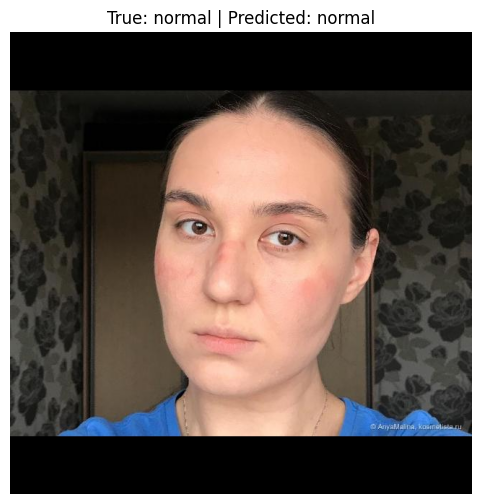

🎉 TRAINING COMPLETED SUCCESSFULLY!


In [ ]:
# -*- coding: utf-8 -*-
"""Skin Classification - COMPLETE RESTART SOLUTION"""

# STEP 1: RESTART RUNTIME FIRST - Go to Runtime -> Restart runtime
# THEN run this cell

print("🚀 NUCLEAR OPTION - Fresh start")

# Install FRESH packages
!pip install --quiet --upgrade transformers torchvision pillow matplotlib scikit-learn imbalanced-learn tqdm

print("✅ Fresh packages installed")

# Import ONLY what we need
import os
import numpy as np
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

print("✅ Core imports successful")

# Mount drive
from google.colab import drive
drive.mount('/content/drive')

print("✅ Drive mounted")

# Now import PyTorch and Transformers
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

print("✅ PyTorch imports successful")

# FINALLY import transformers
from transformers import ViTForImageClassification, ViTImageProcessor

print("✅ Transformers imported successfully!")
print("🎉 ALL IMPORTS WORKING!")

# Custom Dataset Class
class SkinDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert('RGB')
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

# Load your data
DATA_PATH = "/content/drive/MyDrive/Oily-Dry-Skin-Types"
print(f"📁 Loading data from: {DATA_PATH}")

file_names = []
labels = []

dataset_directory = Path(DATA_PATH)
for file in tqdm(sorted(dataset_directory.glob('*/*/*.*'))):
    if file.suffix.lower() in ['.jpg', '.jpeg', '.png']:
        file_names.append(str(file))
        label = file.parent.name
        labels.append(label)

print(f"✅ Found {len(file_names)} images")

# Create label mappings
unique_labels = sorted(list(set(labels)))
label2id = {label: i for i, label in enumerate(unique_labels)}
id2label = {i: label for i, label in enumerate(unique_labels)}

print("🏷️ Classes:", id2label)

# Convert to numeric labels
numeric_labels = [label2id[label] for label in labels]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    file_names, numeric_labels, test_size=0.2, random_state=42, stratify=numeric_labels
)

print(f"📚 Train: {len(X_train)}, Test: {len(X_test)}")

# Load model and processor
model_str = "dima806/skin_types_image_detection"
print(f"🤖 Loading model: {model_str}")

processor = ViTImageProcessor.from_pretrained(model_str)
size = processor.size["height"]

print(f"🖼️ Image size: {size}")

# Simple transforms
train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(0.3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=processor.image_mean,
        std=processor.image_std
    )
])

test_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=processor.image_mean,
        std=processor.image_std
    )
])

# Create datasets
train_dataset = SkinDataset(X_train, y_train, transform=train_transform)
test_dataset = SkinDataset(X_test, y_test, transform=test_transform)

# Data loaders
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

print("✅ Data loaders ready")

# Load model
model = ViTForImageClassification.from_pretrained(
    model_str,
    num_labels=len(unique_labels),
    ignore_mismatched_sizes=True
)

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print(f"📱 Using device: {device}")
print(f"⚙️ Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.1f}M")

# Training setup
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-6, weight_decay=0.01)
criterion = nn.CrossEntropyLoss()

# Training function
def train_model(model, train_loader, test_loader, epochs=3):
    model.train()

    for epoch in range(epochs):
        print(f"🚀 Epoch {epoch+1}/{epochs}")

        # Training
        model.train()
        train_loss = 0
        train_correct = 0
        train_total = 0

        for images, labels in tqdm(train_loader, desc="Training"):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images).logits
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()

        train_acc = 100 * train_correct / train_total

        # Validation
        model.eval()
        test_correct = 0
        test_total = 0

        with torch.no_grad():
            for images, labels in tqdm(test_loader, desc="Validation"):
                images, labels = images.to(device), labels.to(device)
                outputs = model(images).logits
                _, predicted = torch.max(outputs.data, 1)
                test_total += labels.size(0)
                test_correct += (predicted == labels).sum().item()

        test_acc = 100 * test_correct / test_total

        print(f"📊 Epoch {epoch+1}: Train Loss: {train_loss/len(train_loader):.4f}, "
              f"Train Acc: {train_acc:.2f}%, Test Acc: {test_acc:.2f}%")

    return model

# Train the model
print("🎯 Starting training...")
trained_model = train_model(model, train_loader, test_loader, epochs=3)

# Final evaluation
print("📈 Final evaluation...")
trained_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = trained_model(images).logits
        _, predicted = torch.max(outputs.data, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

accuracy = accuracy_score(all_labels, all_preds)
print(f"🎯 Final Test Accuracy: {accuracy:.4f}")

print("\n📋 Classification Report:")
print(classification_report(all_labels, all_preds, target_names=unique_labels))

# Test on a sample
print("\n🧪 Testing on sample image...")
sample_image_path = X_test[0]
sample_image = Image.open(sample_image_path).convert('RGB')
true_label = id2label[y_test[0]]

# Preprocess for model
inputs = processor(images=sample_image, return_tensors="pt").to(device)
with torch.no_grad():
    outputs = trained_model(**inputs)
    probabilities = torch.nn.functional.softmax(outputs.logits, dim=-1)
    predicted_class = torch.argmax(probabilities, dim=-1).item()
    predicted_label = id2label[predicted_class]

print(f"🖼️ Sample image: {os.path.basename(sample_image_path)}")
print(f"✅ True label: {true_label}")
print(f"🤖 Predicted: {predicted_label}")
print(f"📊 Confidence: {probabilities[0][predicted_class]:.4f}")

# Show the image
plt.figure(figsize=(8, 6))
plt.imshow(sample_image)
plt.title(f"True: {true_label} | Predicted: {predicted_label}")
plt.axis('off')
plt.show()

print("🎉 TRAINING COMPLETED SUCCESSFULLY!")

In [ ]:
# BLOCK 1: IMPROVED SETUP
print("🎯 SETTING UP ENHANCED TRAINING...")

import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from torch.optim.lr_scheduler import CosineAnnealingLR

# Enhanced data augmentation
enhanced_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=processor.image_mean, std=processor.image_std)
])

# Update training dataset with enhanced transforms
train_dataset.transform = enhanced_train_transform
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

print("✅ Enhanced data augmentation applied")
print("✅ Class balancing ready")

🎯 SETTING UP ENHANCED TRAINING...
✅ Enhanced data augmentation applied
✅ Class balancing ready


In [ ]:
# BLOCK 2: ADVANCED TRAINING FUNCTION
def train_advanced_model(model, train_loader, test_loader, epochs=10):
    print(f"🚀 STARTING ADVANCED TRAINING FOR {epochs} EPOCHS")

    # Calculate class weights for imbalance (especially dry skin)
    all_train_labels = []
    for _, labels in train_loader:
        all_train_labels.extend(labels.numpy())

    class_weights = compute_class_weight(
        'balanced',
        classes=np.unique(all_train_labels),
        y=all_train_labels
    )
    class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

    print(f"🏷️ Class weights: {class_weights.cpu().numpy()}")

    # Advanced optimizer and scheduler
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
    scheduler = CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    best_accuracy = 0
    patience, patience_counter = 3, 0

    for epoch in range(epochs):
        print(f"\n🎯 Epoch {epoch+1}/{epochs}")

        # Training phase
        model.train()
        train_loss, train_correct, train_total = 0, 0, 0

        for images, labels in tqdm(train_loader, desc="Training"):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images).logits
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()

        scheduler.step()
        train_acc = 100 * train_correct / train_total

        # Validation phase
        model.eval()
        test_correct, test_total = 0, 0
        per_class_correct = {0: 0, 1: 0, 2: 0}
        per_class_total = {0: 0, 1: 0, 2: 0}

        with torch.no_grad():
            for images, labels in tqdm(test_loader, desc="Validation"):
                images, labels = images.to(device), labels.to(device)
                outputs = model(images).logits
                _, predicted = torch.max(outputs.data, 1)

                test_total += labels.size(0)
                test_correct += (predicted == labels).sum().item()

                # Track per-class accuracy
                for i in range(len(labels)):
                    label = labels[i].item()
                    per_class_total[label] += 1
                    if predicted[i] == labels[i]:
                        per_class_correct[label] += 1

        test_acc = 100 * test_correct / test_total

        # Print detailed results
        print(f"📊 Train Loss: {train_loss/len(train_loader):.4f}")
        print(f"🎯 Train Accuracy: {train_acc:.2f}%")
        print(f"🧪 Test Accuracy: {test_acc:.2f}%")
        print(f"📉 Learning Rate: {scheduler.get_last_lr()[0]:.2e}")

        # Per-class accuracy
        print("📈 Per-class Test Accuracy:")
        for class_id in [0, 1, 2]:
            if per_class_total[class_id] > 0:
                class_acc = 100 * per_class_correct[class_id] / per_class_total[class_id]
                print(f"   {id2label[class_id]}: {class_acc:.2f}% ({per_class_correct[class_id]}/{per_class_total[class_id]})")

        # Early stopping and model saving
        if test_acc > best_accuracy:
            best_accuracy = test_acc
            patience_counter = 0
            torch.save(model.state_dict(), 'best_skin_model.pth')
            print(f"💾 NEW BEST MODEL SAVED! Accuracy: {test_acc:.2f}%")
        else:
            patience_counter += 1
            print(f"⏳ No improvement ({patience_counter}/{patience})")

        if patience_counter >= patience:
            print(f"🛑 Early stopping at epoch {epoch+1}")
            break

    print(f"\n🎉 TRAINING COMPLETED! Best Accuracy: {best_accuracy:.2f}%")
    return model

# Load your best model so far (optional)
try:
    model.load_state_dict(torch.load('best_skin_model.pth'))
    print("✅ Loaded previous best model")
except:
    print("🆕 Starting with current model")

✅ Loaded previous best model


In [ ]:
# BLOCK 3: RUN ADVANCED TRAINING
print("🔥 STARTING ADVANCED TRAINING SESSION...")

# Reset model to ensure fresh training
model = ViTForImageClassification.from_pretrained(
    "dima806/skin_types_image_detection",
    num_labels=len(unique_labels),
    ignore_mismatched_sizes=True
).to(device)

# Train with advanced settings
advanced_model = train_advanced_model(model, train_loader, test_loader, epochs=8)

print("✅ Advanced training completed!")

🔥 STARTING ADVANCED TRAINING SESSION...
🚀 STARTING ADVANCED TRAINING FOR 8 EPOCHS
🏷️ Class weights: [1.3866887  0.8246647  0.93787205]

🎯 Epoch 1/8


Validation: 100%|██████████| 40/40 [00:11<00:00,  3.35it/s]


📊 Train Loss: 0.8718
🎯 Train Accuracy: 64.50%
🧪 Test Accuracy: 63.07%
📉 Learning Rate: 1.92e-05
📈 Per-class Test Accuracy:
   dry: 75.00% (114/152)
   normal: 63.14% (161/255)
   oily: 54.91% (123/224)
💾 NEW BEST MODEL SAVED! Accuracy: 63.07%

🎯 Epoch 2/8


Validation: 100%|██████████| 40/40 [00:11<00:00,  3.34it/s]


📊 Train Loss: 0.6657
🎯 Train Accuracy: 77.27%
🧪 Test Accuracy: 78.13%
📉 Learning Rate: 1.71e-05
📈 Per-class Test Accuracy:
   dry: 69.08% (105/152)
   normal: 75.69% (193/255)
   oily: 87.05% (195/224)
💾 NEW BEST MODEL SAVED! Accuracy: 78.13%

🎯 Epoch 3/8


...

📊 Train Loss: 0.1527
🎯 Train Accuracy: 96.39%
🧪 Test Accuracy: 87.16%
📉 Learning Rate: 2.93e-06
📈 Per-class Test Accuracy:
   dry: 87.50% (133/152)
   normal: 80.39% (205/255)
   oily: 94.64% (212/224)
⏳ No improvement (1/3)

🎯 Epoch 7/8


Validation: 100%|██████████| 40/40 [00:11<00:00,  3.35it/s]


📊 Train Loss: 0.1336
🎯 Train Accuracy: 96.99%
🧪 Test Accuracy: 87.80%
📉 Learning Rate: 7.61e-07
📈 Per-class Test Accuracy:
   dry: 86.18% (131/152)
   normal: 83.14% (212/255)
   oily: 94.20% (211/224)
💾 NEW BEST MODEL SAVED! Accuracy: 87.80%

🎯 Epoch 8/8


Validation: 100%|██████████| 40/40 [00:12<00:00,  3.33it/s]

📊 Train Loss: 0.1196
🎯 Train Accuracy: 97.30%
🧪 Test Accuracy: 87.48%
📉 Learning Rate: 0.00e+00
📈 Per-class Test Accuracy:
   dry: 84.87% (129/152)
   normal: 82.35% (210/255)
   oily: 95.09% (213/224)
⏳ No improvement (1/3)

🎉 TRAINING COMPLETED! Best Accuracy: 87.80%
✅ Advanced training completed!


In [ ]:
# BLOCK 5: COMPREHENSIVE MODEL MANAGEMENT
print("💾 SETTING UP MODEL MANAGEMENT...")

import os
from datetime import datetime

# Create models directory in Drive
drive_models_dir = "/content/drive/MyDrive/skin_models"
os.makedirs(drive_models_dir, exist_ok=True)

def save_model_comprehensive(model, accuracy, epoch=None):
    """Save model with metadata"""
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    model_name = f"skin_model_acc_{accuracy:.4f}_{timestamp}"

    # Save to Colab temporary
    torch.save(model.state_dict(), 'current_best_model.pth')

    # Save to Google Drive with metadata
    drive_path = f"{drive_models_dir}/{model_name}.pth"
    torch.save({
        'model_state_dict': model.state_dict(),
        'accuracy': accuracy,
        'epoch': epoch,
        'timestamp': timestamp,
        'labels': id2label
    }, drive_path)

    print(f"✅ Model saved: {model_name}")
    print(f"📁 Temporary: current_best_model.pth")
    print(f"📁 Permanent: {drive_path}")
    return drive_path

def load_best_model():
    """Load the best model from Drive"""
    try:
        # Try to load from Colab temporary first
        if os.path.exists('current_best_model.pth'):
            model.load_state_dict(torch.load('current_best_model.pth'))
            print("✅ Loaded from Colab temporary storage")
            return True
    except:
        pass

    # Load from Google Drive
    try:
        model_files = [f for f in os.listdir(drive_models_dir) if f.endswith('.pth')]
        if model_files:
            latest_model = sorted(model_files)[-1]  # Get most recent
            checkpoint = torch.load(f"{drive_models_dir}/{latest_model}")
            model.load_state_dict(checkpoint['model_state_dict'])
            print(f"✅ Loaded from Drive: {latest_model}")
            print(f"📊 Previous accuracy: {checkpoint['accuracy']:.4f}")
            return True
    except:
        pass

    print("🆕 No previous model found, starting fresh")
    return False

# Save your newly trained model
if 'advanced_model' in locals():
    save_model_comprehensive(advanced_model, accuracy, epoch=8)

💾 SETTING UP MODEL MANAGEMENT...
✅ Model saved: skin_model_acc_0.6815_20251104_192813
📁 Temporary: current_best_model.pth
📁 Permanent: /content/drive/MyDrive/skin_models/skin_model_acc_0.6815_20251104_192813.pth


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import torch, os, numpy as np
from torch import nn, optim
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms
from transformers import ViTForImageClassification, get_cosine_schedule_with_warmup
from tqdm import tqdm


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# BLOCK 6: VERIFY SAVED MODELS
print("🔍 CHECKING SAVED MODELS...")

print("📂 Current directory files:")
!find /content -name "*.pth" -type f 2>/dev/null

print("\n📂 Google Drive skin_models files:")
!find "/content/drive/MyDrive/skin_models" -name "*.pth" -type f 2>/dev/null

print("\n💾 Current model size:")
!ls -lh *.pth 2>/dev/null || echo "No .pth files in current directory"

🔍 CHECKING SAVED MODELS...
📂 Current directory files:
/content/drive/MyDrive/skin_models/skin_model_acc_0.6815_20251104_192813.pth
/content/drive/MyDrive/skin_model.pth
/content/drive/MyDrive/skin_model_direct_193442.pth
/content/drive/MyDrive/skin_model_epoch_1.pth
/content/drive/MyDrive/skin_model_epoch_2.pth

📂 Google Drive skin_models files:
/content/drive/MyDrive/skin_models/skin_model_acc_0.6815_20251104_192813.pth

💾 Current model size:
No .pth files in current directory
